# Nepal Earthquake Damage Prediction
## 04 CatBoost, LightGBM Tuning, and Probability Ensemble

**Goal.** Improve on Notebook 03 without changing its raw data or fixed train/validation split. This notebook:

1. tunes a small, controlled set of LightGBM configurations on one-hot features;
2. trains CatBoost directly on categorical variables;
3. selects a probability-blending weight using the validation set; and
4. retrains the selected models on all labelled observations before writing a DrivenData submission.

### Important evaluation rule
The test set is never used for model selection. The same fixed validation split from Notebooks 01鈥?2 is used for all comparisons. The final public leaderboard score is the external check after submission.

### Required packages
Run this once in the intended Python environment if required:

```bash
pip install catboost lightgbm
```


In [1]:
# Run this cell once before the imports below.
# It installs packages into the SAME Python environment used by this notebook.
import sys, subprocess, importlib.util

required_packages = ["lightgbm", "catboost"]
missing_packages = [pkg for pkg in required_packages if importlib.util.find_spec(pkg) is None]

print("Notebook Python executable:", sys.executable)
if missing_packages:
    print("Installing missing packages:", missing_packages)
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *missing_packages
    ])
    print("Installation complete. Restart the kernel, then run all cells from the top.")
else:
    print("CatBoost and LightGBM are already available.")


Notebook Python executable: e:\Python\python.exe
CatBoost and LightGBM are already available.


In [2]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    f1_score, recall_score, mean_absolute_error, cohen_kappa_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

try:
    from lightgbm import LGBMClassifier, early_stopping, log_evaluation
    from catboost import CatBoostClassifier
except ImportError as exc:
    raise ImportError(
        "This notebook needs CatBoost and LightGBM. Install them with: "
        "pip install catboost lightgbm"
    ) from exc

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)

RANDOM_STATE = 42
N_JOBS = -1

# Works whether Jupyter starts in group_project/ or group_project/Modeling/.
CWD = Path.cwd()
if (CWD / "Preprocess & EDA").exists():
    PROJECT_ROOT = CWD
elif (CWD.parent / "Preprocess & EDA").exists():
    PROJECT_ROOT = CWD.parent
else:
    raise FileNotFoundError(
        "Could not locate the project root containing 'Preprocess & EDA'."
    )

PREP_DIR = PROJECT_ROOT / "Preprocess & EDA"
RAW_DIR = PREP_DIR / "raw_data"
SUPP_DIR = PREP_DIR / "supplementary_processed_data"
MODELING_DIR = PROJECT_ROOT / "Modeling"
RESULT_DIR = MODELING_DIR / "results_04_tuning"
FIG_DIR = MODELING_DIR / "figures_04_tuning"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Results:", RESULT_DIR)


Project root: c:\Users\王柄尧\OneDrive\桌面\group_project\group_project
Results: c:\Users\王柄尧\OneDrive\桌面\group_project\group_project\Modeling\results_04_tuning


## 1. Load complete features and reproduce the fixed split

The `.pkl` files preserve categorical dtypes. `building_id` is retained for matching labels and creating the submission, but it is never supplied to a model.


In [3]:
required = [
    SUPP_DIR / "train_features_complete.pkl",
    SUPP_DIR / "test_features_complete.pkl",
    SUPP_DIR / "train_validation_split_complete.csv",
    RAW_DIR / "train_labels.csv",
    RAW_DIR / "submission_format.csv",
]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Missing required inputs:\n" + "\n".join(missing))

train_features = pd.read_pickle(SUPP_DIR / "train_features_complete.pkl")
test_features = pd.read_pickle(SUPP_DIR / "test_features_complete.pkl")
labels = pd.read_csv(RAW_DIR / "train_labels.csv")
split_map = pd.read_csv(SUPP_DIR / "train_validation_split_complete.csv")
submission_format = pd.read_csv(RAW_DIR / "submission_format.csv")

label_map = labels.set_index("building_id")["damage_grade"]
split_lookup = split_map.set_index("building_id")["split"]
y_all = train_features["building_id"].map(label_map).astype(int)
split = train_features["building_id"].map(split_lookup)

assert split.notna().all()
assert set(split.unique()) == {"train", "validation"}
assert train_features["building_id"].is_unique
assert test_features["building_id"].is_unique

X_all = train_features.drop(columns="building_id").copy()
X_test_all = test_features.drop(columns="building_id").copy()
X_train = X_all.loc[split.eq("train")].copy()
X_valid = X_all.loc[split.eq("validation")].copy()
y_train = y_all.loc[split.eq("train")].copy()
y_valid = y_all.loc[split.eq("validation")].copy()

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Test rows:", len(X_test_all))
display(pd.crosstab(split, y_all, normalize="index").round(4))


Training rows: 208480
Validation rows: 52121
Test rows: 86868


building_id,1,2,3
building_id,,,
train,0.0964,0.5689,0.3347
validation,0.0964,0.5689,0.3347


## 2. Shared evaluation functions

Micro F1 is the DrivenData metric. Because this is a single-label multiclass task, Micro F1 equals accuracy; Macro F1 and Grade-3 recall are retained so that minority-class performance is not hidden.


In [4]:
def catastrophic_error_rate(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) == 2))

def evaluate(y_true, y_pred, name, seconds=np.nan):
    return {
        "Model": name,
        "Micro F1": f1_score(y_true, y_pred, average="micro"),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Grade 3 Recall": recall_score(y_true, y_pred, labels=[3], average=None, zero_division=0)[0],
        "Ordinal MAE": mean_absolute_error(y_true, y_pred),
        "QWK": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
        "CER": catastrophic_error_rate(y_true, y_pred),
        "Train seconds": seconds,
    }

def labels_from_proba(probabilities):
    # Both models use classes 1, 2, 3 in this notebook.
    return np.argmax(probabilities, axis=1) + 1


## 3. Prepare two valid feature representations

- **LightGBM:** one-hot encoding prevents categorical codes from being treated as ordinal numbers.
- **CatBoost:** receives categorical columns directly as strings, which lets it learn category effects without a high-dimensional one-hot matrix.

Both encoders are fitted on the training split only.


In [5]:
GEO_COLS = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]
categorical_cols = [
    c for c in X_train.columns
    if str(X_train[c].dtype) in ("object", "category") or c in GEO_COLS
]
numeric_cols = [c for c in X_train.columns if c not in categorical_cols]

ohe = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore", min_frequency=5, dtype=np.float32),
        categorical_cols,
    ),
    ("numeric", "passthrough", numeric_cols),
])

t0 = time.time()
X_train_ohe = ohe.fit_transform(X_train)
X_valid_ohe = ohe.transform(X_valid)
print("One-hot shape:", X_train_ohe.shape)
print("One-hot preprocessing seconds:", round(time.time() - t0, 2))

def catboost_frame(frame):
    result = frame.copy()
    for col in categorical_cols:
        result[col] = result[col].astype("string").fillna("__MISSING__").astype(str)
    for col in numeric_cols:
        result[col] = pd.to_numeric(result[col], errors="coerce").fillna(result[col].median())
    return result

X_train_cb = catboost_frame(X_train)
X_valid_cb = catboost_frame(X_valid)
cat_feature_indices = [X_train_cb.columns.get_loc(c) for c in categorical_cols]
print("Categorical columns for CatBoost:", len(categorical_cols))


One-hot shape: (208480, 9759)
One-hot preprocessing seconds: 1.69
Categorical columns for CatBoost: 13


## 4. Tune a compact LightGBM candidate set

This is a deliberately small manual search rather than a large search over the validation set. Early stopping determines the effective number of boosting iterations for each candidate.


In [6]:
lgbm_candidates = [
    {
        "name": "LGBM_balanced",
        "n_estimators": 1200, "learning_rate": 0.04, "num_leaves": 63,
        "min_child_samples": 20, "subsample": 0.90, "colsample_bytree": 0.90,
        "reg_lambda": 1.0, "reg_alpha": 0.0,
    },
    {
        "name": "LGBM_deeper",
        "n_estimators": 1400, "learning_rate": 0.035, "num_leaves": 127,
        "min_child_samples": 24, "subsample": 0.90, "colsample_bytree": 0.95,
        "reg_lambda": 2.0, "reg_alpha": 0.10,
    },
    {
        "name": "LGBM_regularized",
        "n_estimators": 1400, "learning_rate": 0.035, "num_leaves": 63,
        "min_child_samples": 35, "subsample": 0.95, "colsample_bytree": 0.90,
        "reg_lambda": 4.0, "reg_alpha": 0.15,
    },
]

lgbm_runs = []
for params in lgbm_candidates:
    run_params = params.copy()
    name = run_params.pop("name")
    model = LGBMClassifier(
        objective="multiclass", num_class=3, random_state=RANDOM_STATE,
        n_jobs=N_JOBS, verbosity=-1, **run_params
    )
    t0 = time.time()
    model.fit(
        X_train_ohe, y_train,
        eval_set=[(X_valid_ohe, y_valid)],
        eval_metric="multi_logloss",
        callbacks=[early_stopping(100, verbose=False), log_evaluation(0)],
    )
    proba = model.predict_proba(X_valid_ohe)
    pred = labels_from_proba(proba)
    row = evaluate(y_valid, pred, name, time.time() - t0)
    row["Best iteration"] = int(model.best_iteration_ or run_params["n_estimators"])
    row["params"] = run_params
    lgbm_runs.append({"model": model, "proba": proba, "row": row})

lgbm_table = pd.DataFrame([r["row"] for r in lgbm_runs]).sort_values("Micro F1", ascending=False)
display(lgbm_table.drop(columns="params").round(4))
best_lgbm_run = max(lgbm_runs, key=lambda r: (r["row"]["Micro F1"], r["row"]["Macro F1"]))


,Model,Micro F1,Macro F1,Grade 3 Recall,Ordinal MAE,QWK,CER,Train seconds,Best iteration
1,LGBM_deeper,0.7516,0.7029,0.6455,0.2519,0.6262,0.0035,78.7712,1332
0,LGBM_balanced,0.7508,0.7011,0.6339,0.2526,0.6221,0.0034,42.5179,1200
2,LGBM_regularized,0.7481,0.6966,0.6349,0.2551,0.6188,0.0033,43.2815,1398


## 5. Tune CatBoost with native categorical features

CatBoost is particularly appropriate here because the dataset contains high-cardinality geographic IDs and anonymous category codes. It uses the category values directly rather than treating them as ordered integers.


In [7]:
catboost_candidates = [
    {
        "name": "CatBoost_depth8",
        "iterations": 1600, "depth": 8, "learning_rate": 0.05,
        "l2_leaf_reg": 5.0, "random_strength": 0.5, "bagging_temperature": 0.5,
    },
    {
        "name": "CatBoost_depth9",
        "iterations": 1600, "depth": 9, "learning_rate": 0.045,
        "l2_leaf_reg": 7.0, "random_strength": 0.8, "bagging_temperature": 0.5,
    },
    {
        "name": "CatBoost_regularized",
        "iterations": 1800, "depth": 8, "learning_rate": 0.04,
        "l2_leaf_reg": 10.0, "random_strength": 1.0, "bagging_temperature": 1.0,
    },
]

catboost_runs = []
for params in catboost_candidates:
    run_params = params.copy()
    name = run_params.pop("name")
    model = CatBoostClassifier(
        loss_function="MultiClass", eval_metric="MultiClass",
        random_seed=RANDOM_STATE, thread_count=N_JOBS,
        allow_writing_files=False, verbose=200, **run_params
    )
    t0 = time.time()
    model.fit(
        X_train_cb, y_train,
        cat_features=cat_feature_indices,
        eval_set=(X_valid_cb, y_valid),
        early_stopping_rounds=120,
        use_best_model=True,
        verbose=200,
    )
    proba = model.predict_proba(X_valid_cb)
    pred = labels_from_proba(proba)
    row = evaluate(y_valid, pred, name, time.time() - t0)
    best_iter = model.get_best_iteration()
    row["Best iteration"] = int(best_iter if best_iter and best_iter > 0 else run_params["iterations"])
    row["params"] = run_params
    catboost_runs.append({"model": model, "proba": proba, "row": row})

catboost_table = pd.DataFrame([r["row"] for r in catboost_runs]).sort_values("Micro F1", ascending=False)
display(catboost_table.drop(columns="params").round(4))
best_catboost_run = max(catboost_runs, key=lambda r: (r["row"]["Micro F1"], r["row"]["Macro F1"]))


0:	learn: 1.0614835	test: 1.0606778	best: 1.0606778 (0)	total: 555ms	remaining: 14m 47s
200:	learn: 0.5835324	test: 0.5658139	best: 0.5658139 (200)	total: 1m 53s	remaining: 13m 8s
400:	learn: 0.5698159	test: 0.5581548	best: 0.5581548 (400)	total: 3m 56s	remaining: 11m 45s
600:	learn: 0.5627246	test: 0.5553935	best: 0.5553935 (600)	total: 5m 49s	remaining: 9m 41s
800:	learn: 0.5567550	test: 0.5537752	best: 0.5537752 (800)	total: 7m 45s	remaining: 7m 43s
1000:	learn: 0.5516817	test: 0.5527058	best: 0.5527058 (1000)	total: 9m 36s	remaining: 5m 44s
1200:	learn: 0.5463235	test: 0.5517989	best: 0.5517989 (1200)	total: 11m 25s	remaining: 3m 47s
1400:	learn: 0.5416530	test: 0.5513061	best: 0.5513061 (1400)	total: 13m 12s	remaining: 1m 52s
1599:	learn: 0.5368567	test: 0.5506938	best: 0.5506902 (1595)	total: 15m 2s	remaining: 0us

bestTest = 0.5506902494
bestIteration = 1595

Shrink model to first 1596 iterations.
0:	learn: 1.0652909	test: 1.0644380	best: 1.0644380 (0)	total: 543ms	remaining: 14

,Model,Micro F1,Macro F1,Grade 3 Recall,Ordinal MAE,QWK,CER,Train seconds,Best iteration
1,CatBoost_depth9,0.7528,0.7045,0.6460,0.2503,0.6280,0.0032,1717.6608,1597
0,CatBoost_depth8,0.7527,0.7039,0.6461,0.2503,0.6282,0.0030,904.1449,1595
2,CatBoost_regularized,0.7518,0.7032,0.6441,0.2512,0.6269,0.0030,1445.6183,1798


## 6. Select a probability ensemble on the validation set

The ensemble combines class probabilities, not hard labels:

\[ P_{blend} = w P_{CatBoost} + (1-w) P_{LightGBM} \]

Only adopt the blend if it improves or matches the best individual validation model.


,CatBoost weight,Micro F1,Macro F1,Grade 3 Recall,CER
12,0.60,0.7559,0.7075,0.6492,0.0031
11,0.55,0.7557,0.7073,0.6484,0.0031
13,0.65,0.7555,0.7071,0.6489,0.0031
14,0.70,0.7554,0.7073,0.6489,0.0031
9,0.45,0.7553,0.7069,0.6473,0.0032
7,0.35,0.7553,0.7072,0.6480,0.0032
10,0.50,0.7553,0.7067,0.6472,0.0032
8,0.40,0.7552,0.7070,0.6476,0.0032
6,0.30,0.7549,0.7067,0.6476,0.0032
15,0.75,0.7545,0.7061,0.6477,0.0031


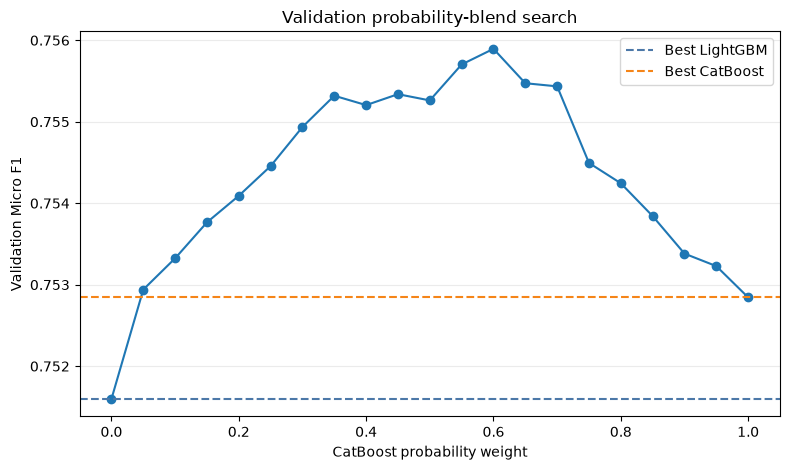

Best individual: CatBoost_depth9 0.75284
Best blend: 0.6 0.75589
Use blend for final submission? True


In [8]:
blend_rows = []
for catboost_weight in np.linspace(0, 1, 21):
    blend_proba = (
        catboost_weight * best_catboost_run["proba"]
        + (1 - catboost_weight) * best_lgbm_run["proba"]
    )
    blend_pred = labels_from_proba(blend_proba)
    row = evaluate(y_valid, blend_pred, f"Blend_cat_{catboost_weight:.2f}")
    row["CatBoost weight"] = catboost_weight
    blend_rows.append(row)

blend_table = pd.DataFrame(blend_rows).sort_values(
    ["Micro F1", "Macro F1"], ascending=False
)
best_blend = blend_table.iloc[0].to_dict()
display(blend_table[["CatBoost weight", "Micro F1", "Macro F1", "Grade 3 Recall", "CER"]].round(4))

all_results = pd.concat([
    lgbm_table.drop(columns="params"),
    catboost_table.drop(columns="params"),
    pd.DataFrame([best_blend]),
], ignore_index=True).sort_values("Micro F1", ascending=False)
all_results.to_csv(RESULT_DIR / "04_validation_model_results.csv", index=False)
blend_table.to_csv(RESULT_DIR / "04_blend_weight_search.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(blend_table.sort_values("CatBoost weight")["CatBoost weight"],
        blend_table.sort_values("CatBoost weight")["Micro F1"], marker="o")
ax.axhline(best_lgbm_run["row"]["Micro F1"], color="#4C78A8", linestyle="--", label="Best LightGBM")
ax.axhline(best_catboost_run["row"]["Micro F1"], color="#F58518", linestyle="--", label="Best CatBoost")
ax.set(xlabel="CatBoost probability weight", ylabel="Validation Micro F1", title="Validation probability-blend search")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_blend_weight_search.png", dpi=300, bbox_inches="tight")
plt.show()

best_individual = max(
    [best_lgbm_run["row"], best_catboost_run["row"]],
    key=lambda r: (r["Micro F1"], r["Macro F1"]),
)
use_blend = (
    best_blend["Micro F1"] > best_individual["Micro F1"]
    or (best_blend["Micro F1"] == best_individual["Micro F1"]
        and best_blend["Macro F1"] >= best_individual["Macro F1"])
)
print("Best individual:", best_individual["Model"], round(best_individual["Micro F1"], 5))
print("Best blend:", round(best_blend["CatBoost weight"], 2), round(best_blend["Micro F1"], 5))
print("Use blend for final submission?", use_blend)


## 7. Error analysis for the selected validation solution


Model             Blend (CatBoost weight=0.60)
Micro F1                              0.755895
Macro F1                              0.707516
Grade 3 Recall                         0.64922
Ordinal MAE                           0.247232
QWK                                   0.632476
CER                                   0.003127
Train seconds                              NaN


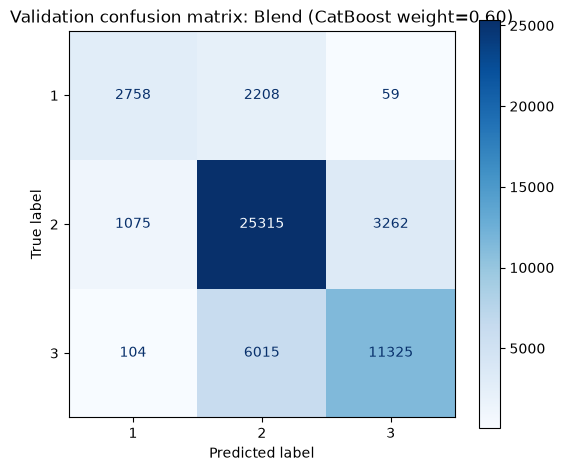

In [9]:
selected_weight = float(best_blend["CatBoost weight"]) if use_blend else None
if use_blend:
    selected_valid_proba = (
        selected_weight * best_catboost_run["proba"]
        + (1 - selected_weight) * best_lgbm_run["proba"]
    )
    selected_name = f"Blend (CatBoost weight={selected_weight:.2f})"
elif best_lgbm_run["row"]["Micro F1"] >= best_catboost_run["row"]["Micro F1"]:
    selected_valid_proba = best_lgbm_run["proba"]
    selected_name = best_lgbm_run["row"]["Model"]
else:
    selected_valid_proba = best_catboost_run["proba"]
    selected_name = best_catboost_run["row"]["Model"]

selected_valid_pred = labels_from_proba(selected_valid_proba)
selected_metrics = evaluate(y_valid, selected_valid_pred, selected_name)
print(pd.Series(selected_metrics).to_string())

fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay.from_predictions(y_valid, selected_valid_pred, labels=[1, 2, 3], cmap="Blues", ax=ax)
ax.set_title(f"Validation confusion matrix: {selected_name}")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_selected_model_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


## 8. Retrain the selected model(s) on all labelled data and create a submission

The chosen validation architecture is re-fitted using every labelled building. The number of iterations is taken from early stopping on the validation run, so the final fit does not need the validation labels.


In [10]:
# Refit one-hot transformer and LightGBM on all labelled data.
X_full = X_all.copy()
X_test = X_test_all.copy()

full_ohe = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore", min_frequency=5, dtype=np.float32), categorical_cols),
    ("numeric", "passthrough", numeric_cols),
])
X_full_ohe = full_ohe.fit_transform(X_full)
X_test_ohe = full_ohe.transform(X_test)

best_lgbm_params = best_lgbm_run["row"]["params"].copy()
best_lgbm_params["n_estimators"] = best_lgbm_run["row"]["Best iteration"]
final_lgbm = LGBMClassifier(
    objective="multiclass", num_class=3, random_state=RANDOM_STATE,
    n_jobs=N_JOBS, verbosity=-1, **best_lgbm_params
)
final_lgbm.fit(X_full_ohe, y_all)
test_proba_lgbm = final_lgbm.predict_proba(X_test_ohe)

# Refit CatBoost only when it is selected individually or contributes to the selected blend.
test_proba_catboost = None
if use_blend or selected_name.startswith("CatBoost"):
    X_full_cb = catboost_frame(X_full)
    X_test_cb = catboost_frame(X_test)
    best_cat_params = best_catboost_run["row"]["params"].copy()
    best_cat_params["iterations"] = best_catboost_run["row"]["Best iteration"]
    final_catboost = CatBoostClassifier(
        loss_function="MultiClass", random_seed=RANDOM_STATE,
        thread_count=N_JOBS, allow_writing_files=False, verbose=200, **best_cat_params
    )
    final_catboost.fit(X_full_cb, y_all, cat_features=cat_feature_indices, verbose=200)
    test_proba_catboost = final_catboost.predict_proba(X_test_cb)

if use_blend:
    test_proba = selected_weight * test_proba_catboost + (1 - selected_weight) * test_proba_lgbm
elif selected_name.startswith("CatBoost"):
    test_proba = test_proba_catboost
else:
    test_proba = test_proba_lgbm

test_pred = labels_from_proba(test_proba).astype(int)
submission = submission_format[["building_id"]].copy()
submission["damage_grade"] = test_pred

assert submission.shape == submission_format.shape
assert submission["building_id"].equals(submission_format["building_id"])
assert set(submission["damage_grade"].unique()).issubset({1, 2, 3})

submission_path = RESULT_DIR / "04_submission_tuned_lgbm_catboost.csv"
submission.to_csv(submission_path, index=False)

run_summary = {
    "selected_validation_solution": selected_name,
    "selected_catboost_weight": selected_weight,
    "selected_validation_metrics": selected_metrics,
    "best_lgbm": best_lgbm_run["row"],
    "best_catboost": best_catboost_run["row"],
    "submission_path": str(submission_path),
}
with open(RESULT_DIR / "04_tuning_run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_summary, f, ensure_ascii=False, indent=2, default=float)

print("Saved submission:", submission_path)
display(submission.head())
display(submission["damage_grade"].value_counts(normalize=True).sort_index().rename("share").round(4))


0:	learn: 1.0648038	total: 651ms	remaining: 17m 18s
200:	learn: 0.5779091	total: 2m 47s	remaining: 19m 25s
400:	learn: 0.5635425	total: 5m 41s	remaining: 16m 59s
600:	learn: 0.5551653	total: 8m 50s	remaining: 14m 39s
800:	learn: 0.5488133	total: 12m 9s	remaining: 12m 5s
1000:	learn: 0.5436556	total: 15m 13s	remaining: 9m 3s
1200:	learn: 0.5386271	total: 18m 31s	remaining: 6m 6s
1400:	learn: 0.5342563	total: 21m 34s	remaining: 3m 1s
1596:	learn: 0.5296457	total: 24m 22s	remaining: 0us
Saved submission: c:\Users\王柄尧\OneDrive\桌面\group_project\group_project\Modeling\results_04_tuning\04_submission_tuned_lgbm_catboost.csv


,building_id,damage_grade
0,300051,3
1,99355,2
2,890251,2
3,745817,1
4,421793,3


damage_grade
1    0.0749
2    0.6465
3    0.2787
Name: share, dtype: float64

## 9. How to report the result

Report the winning validation metric and the public leaderboard score separately. Do not treat the public score as a replacement for validation. If the ensemble is not better on the fixed validation split, retain the stronger individual model; an ensemble is useful only when it gives a measurable and reproducible validation benefit.
